# About the Dataset

**Context**
- Machine Learning with R by Brett Lantz is a book that provides an introduction to machine learning using R. As far as I can tell, Packt Publishing does not make its datasets available online unless you buy the book and create a user account which can be a problem if you are checking the book out from the library or borrowing the book from a friend. All of these datasets are in the public domain but simply needed some cleaning up and recoding to match the format in the book.
  
- I will not be using R, instead I will be using python. 

**Content**

**Columns**

**age**: age of primary beneficiary

**sex**: insurance contractor gender, female, male

**bmi**: Body mass index, providing an understanding of body, weights that are relatively high or low relative to height,
objective index of body weight (kg / m ^ 2) using the ratio of height to weight, ideally 18.5 to 24.9

**children**: Number of children covered by health insurance / Number of dependents

**smoker**: Smoking

**region**: the beneficiary's residential area in the US, northeast, southeast, southwest, northwest.

**charges**: Individual medical costs billed by health insurance

**Acknowledgements**
 - The dataset is available on GitHub here.
 - This is is the URL to get the datasdet: https://www.kaggle.com/datasets/mirichoi0218/insurance?utm_

**Inspiration**
- The idea is to accurately predict the insurance costs with the given dataset.

# Project Process and Workflow

## Objective
Predict individual medical insurance charges using Linear Regression and evaluate how demographic, lifestyle, and regional factors relate to medical costs.

## Project Workflow

1. **Import Libraries** — Load packages for analysis, visualization, and machine learning.
2. **Load Dataset** — Import the medical insurance dataset.
3. **Data Inspection and Cleaning** — Check missing values, duplicates, data types, and formatting.
4. **Exploratory Data Analysis (EDA)** — Examine distributions, correlations, outliers, and categorical features.
5. **Feature and Target Selection** — Separate predictors (X) from medical charges (y).
6. **Train-Test Split** — Divide data into 70% training and 30% testing.
7. **Data Preprocessing** — Handle missing values, one-hot encode categorical features, and optionally scale numerical features.
8. **Model Training** — Train a Linear Regression model.
9. **Model Predictions** — Predict medical charges using the test dataset.
10. **Model Evaluation** — Calculate MAE, MSE, RMSE, and R².
11. **Model Diagnostics** — Analyze residuals, prediction errors, and model assumptions.
12. **Model Interpretation** — Examine coefficients and identify important predictors.
13. **Cross-Validation** — Evaluate model stability using multiple training folds.
14. **Model Comparison** — Compare Linear Regression, Ridge, and Lasso.
15. **Final Results and Export** — Summarize findings and save the fitted model and preprocessing pipeline.


# Step 1 - Import Libraries
Import the libraries needed for data analysis, visualization, preprocessing, and linear regression.

In [1]:
# Data Analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Regression Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model Export
import joblib

# Step 2 - Loading Data

In [2]:
# created a universal way to load data for excel, csvs, and URLs 
def load_data(file_path, index_col=None):

    # Load CSV
    if file_path.lower().endswith('.csv'):
        df = pd.read_csv(file_path, index_col=index_col)

    # Load Excel
    elif file_path.lower().endswith(('.xlsx', '.xls')):
        df = pd.read_excel(file_path, index_col=index_col)

    # Load HTML Tables
    elif file_path.startswith(('http://', 'https://')):
        df = pd.read_html(file_path, index_col=index_col)[0]

    else:
        raise ValueError('Unsupported file format.')

    # Display Information
    print('Dataset Loaded Successfully'.center(50, '='))
    print(f'Rows: {df.shape[0]}')
    print(f'Columns: {df.shape[1]}')

    display(df.head())

    return df


# Run Function
df = load_data('insurance.csv')

===========Dataset Loaded Successfully============
Rows: 1338
Columns: 7


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Step 3 - Data Inspection

In [3]:
def inspect_data(df, drop_duplicates=True):
    df = df.copy()

    print('DataFrame Info'.center(50,'='))
    df.info()

    print('\n')
    print('Missing Values by Column'.center(50,'='))
    print(df.isnull().sum())

    print('\n')
    print('DataFrame Shape'.center(50,'='))
    print(f'This DataFrame has a total of {df.shape[0]} rows and {df.shape[1]} columns.')

    print('\n')
    print('Duplicate Rows'.center(50,'='))

    duplicates = df.duplicated().sum()
    print(f'Number of Duplicate Rows: {duplicates}.')

    if drop_duplicates and duplicates > 0:
        df = df.drop_duplicates().reset_index(drop=True)
        print(f'Successfully removed {duplicates} duplicate rows.')
        print(f'New DataFrame Shape: {df.shape}')

    print('\n')
    print('DataFrame Column Names'.center(50,'='))
    print(df.columns.to_list())

    return df

df = inspect_data(df, drop_duplicates= True)

==================DataFrame Info==================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


=============Missing Values by Column=============
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


=================DataFrame Shape==================
This DataFrame has a total of 1338 rows and 7 columns.


==================Duplicate Rows==================
Number of Duplicate Rows: 1.
Successfully removed 1 duplicate rows.
New DataFrame Shape: (1337, 7)


===

# Step 3.1 - Data Cleaning - If Necessasary

In [4]:
def capitalize_values(df):

    df = df.copy()

    # Capitalize all column names - makes it look cleaner
    df.columns = df.columns.str.capitalize()
    
    # Select All Text Columns
    for col in df.select_dtypes(include=['object', 'string']).columns:

        # Capitalize Values in columns
        df[col] = df[col].str.strip().str.title()

    print('Capitalization Complete'.center(50, '='))

    return df


# Run Function
df = capitalize_values(df)

display(df.head())

=============Capitalization Complete==============


,Age,Sex,Bmi,Children,Smoker,Region,Charges
0,19,Female,27.900,0,Yes,Southwest,16884.92400
1,18,Male,33.770,1,No,Southeast,1725.55230
2,28,Male,33.000,3,No,Southeast,4449.46200
3,33,Male,22.705,0,No,Northwest,21984.47061
4,32,Male,28.880,0,No,Northwest,3866.85520


# Step 4 - Exploratory Data Analysis (EDA)
Inspect the dataset's structure, missing values, distributions, and correlations.

### Step 4.1 - Distribution 

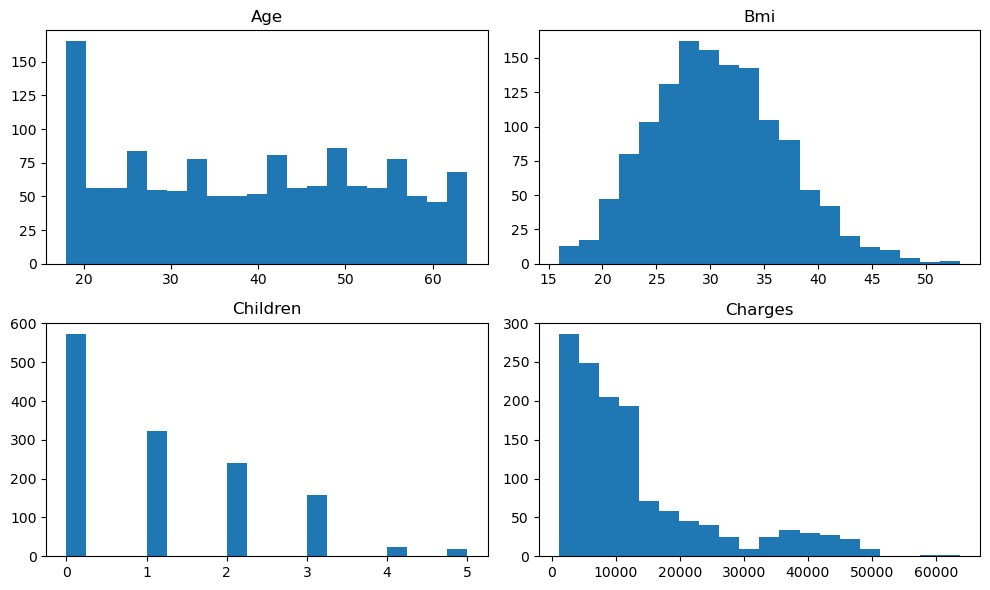

In [5]:
df.hist(figsize=(10,6), bins = 20,grid=False)

plt.tight_layout()
plt.show()

### Step 4.2 - Correlation Matrix

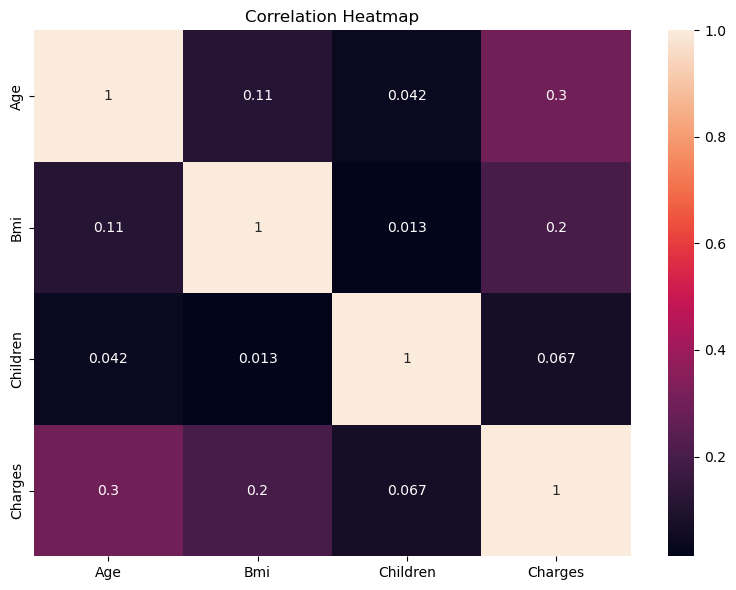

In [6]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(8,6),dpi=100)
sns.heatmap(data = corr,fmt = '.2g',annot = True)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Step 4.3 - Scatter Plots 

### For singular scatterplots 

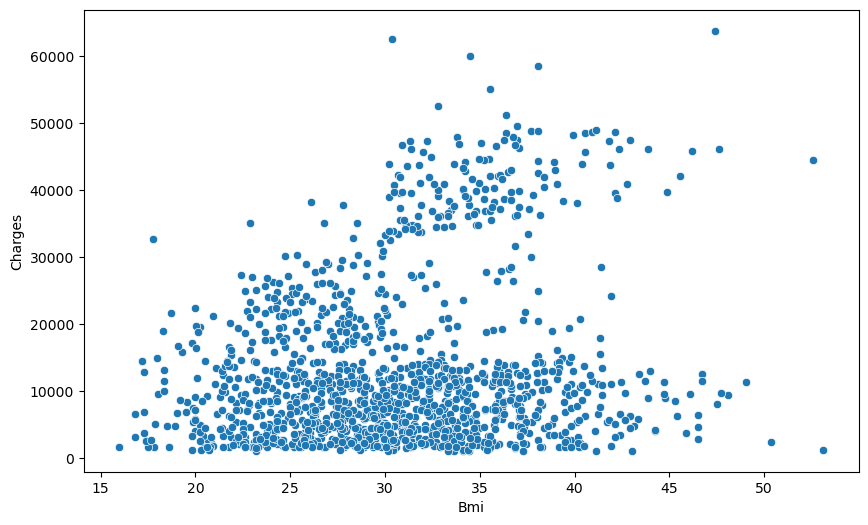

In [7]:
plt.figure(figsize=(10,6), dpi = 100)

sns.scatterplot(data = df, x = 'Bmi', y = 'Charges')

plt.title('')

plt.show()

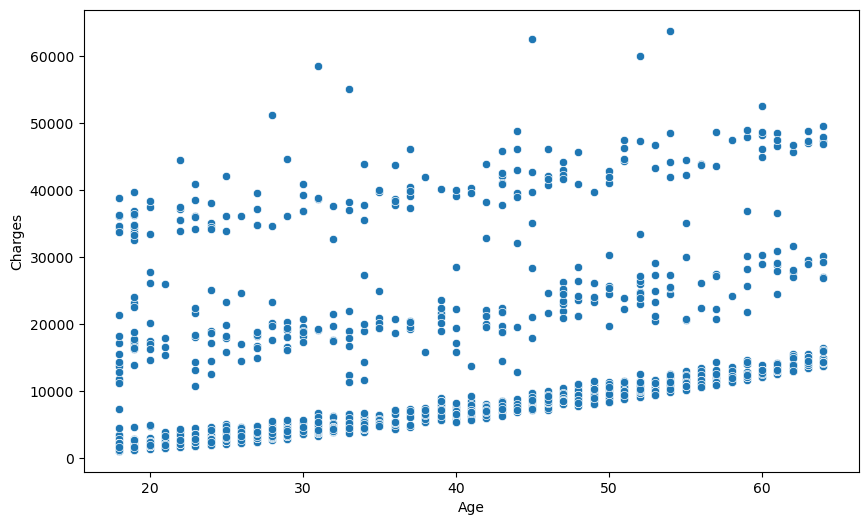

In [8]:
plt.figure(figsize=(10,6), dpi = 100)

sns.scatterplot(data = df, x = 'Age', y = 'Charges')

plt.title('')

plt.show()

### For Mulitple scatterplots at once

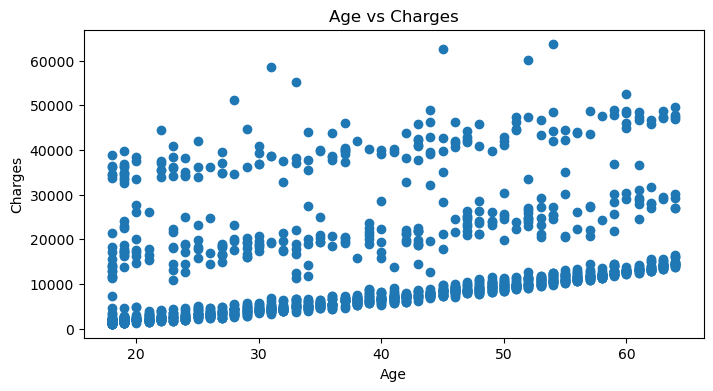

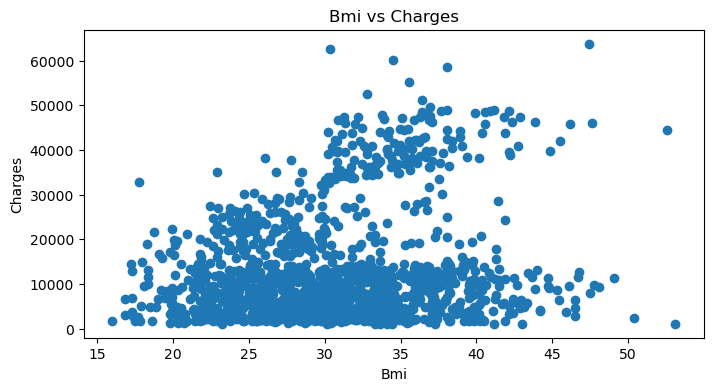

In [9]:
# This is for mulitple scatter plots at once

columns = ['Age','Bmi']

for col in columns:

    plt.figure(figsize=(8, 4),dpi=100)

    plt.scatter(df[col], df['Charges'])

    plt.title(f'{col} vs Charges')
    plt.xlabel(col)
    plt.ylabel('Charges')
    plt.grid(False)

    plt.show()

### Step 4.4 - Outlier Detection

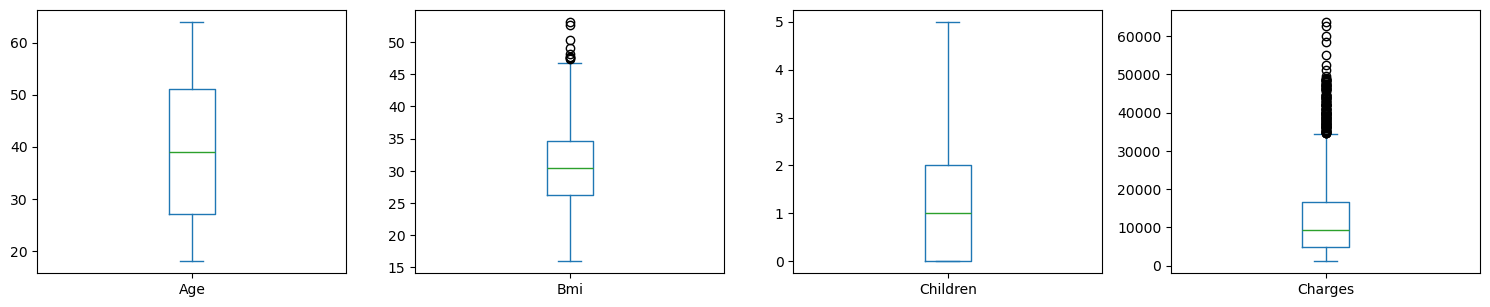

In [10]:
# looking for outliers in the DataFrame
df.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(4, 4),
    figsize=(15, 12),
    sharey=False)

plt.tight_layout()
plt.show()

In [11]:
# looking at specific columns that have outliers 

columns = ['Bmi', 'Charges']

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f'\nOutliers for {col}:')
    print(outliers[['Bmi', 'Charges', col]])



Outliers for Bmi:
        Bmi      Charges    Bmi
116   49.06  11381.32540  49.06
286   48.07   9432.92530  48.07
401   47.52   8083.91980  47.52
543   47.41  63770.42801  47.41
846   50.38   2438.05520  50.38
859   47.60  46113.51100  47.60
1046  52.58  44501.39820  52.58
1087  47.74   9748.91060  47.74
1316  53.13   1163.46270  53.13

Outliers for Charges:
         Bmi      Charges      Charges
14    42.130  39611.75770  39611.75770
19    35.300  36837.46700  36837.46700
23    31.920  37701.87680  37701.87680
29    36.300  38711.00000  38711.00000
30    35.600  35585.57600  35585.57600
...      ...          ...          ...
1299  30.360  62592.87309  62592.87309
1300  30.875  46718.16325  46718.16325
1302  27.800  37829.72420  37829.72420
1312  34.700  36397.57600  36397.57600
1322  40.370  43896.37630  43896.37630

[139 rows x 3 columns]


### Step 4.5 - Top 10 Charges by BMI

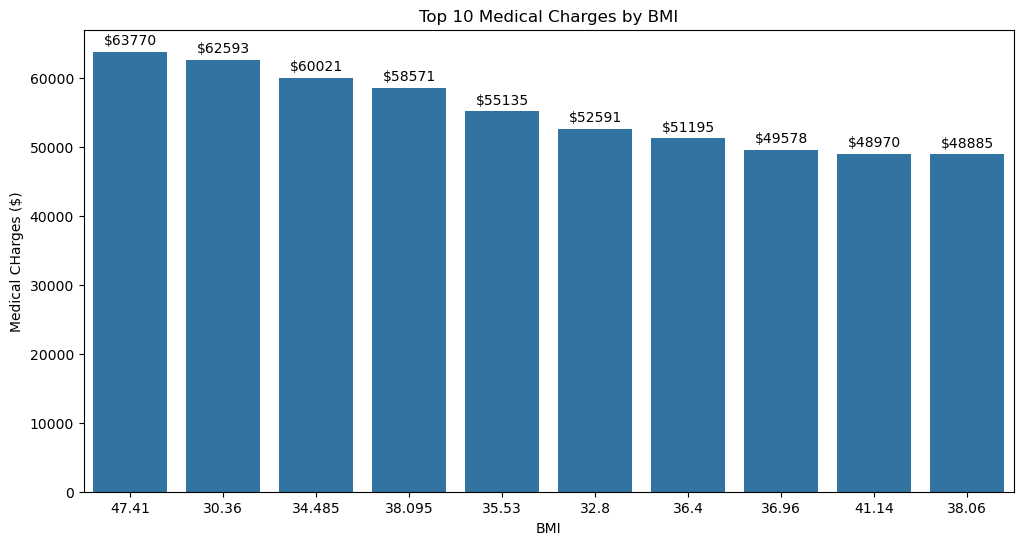

In [47]:
top10 = df.nlargest(10, 'Charges')

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=top10, x=df['Bmi'], y='Charges',order=top10['Bmi'])

for container in ax.containers:
    ax.bar_label(container,fmt='$%.0f',padding=3)

plt.title('Top 10 Medical Charges by BMI')
plt.xlabel('BMI')
plt.ylabel('Medical CHarges ($)')
plt.grid(False)
plt.show()

### Top 10 Medical Charges by BMI

A bar chart was created to examine the 10 patients with the highest medical insurance charges and their corresponding BMI values.

- **Highest Charge:** $63,770, associated with a BMI of 47.41.
- **Second Highest:** $62,593, associated with a BMI of 30.36.
- **BMI Range:** Approximately 30.36 to 47.41.
- **Medical Charges:** Range from approximately $48,885 to $63,770.

**Key Finding:** Patients with the highest medical charges have varying BMI values. While BMI may influence medical costs, other factors, such as smoking status and age, should also be investigated.

### Step 4.6 - Patient Distribution by Region, Smoking Status, and Sex

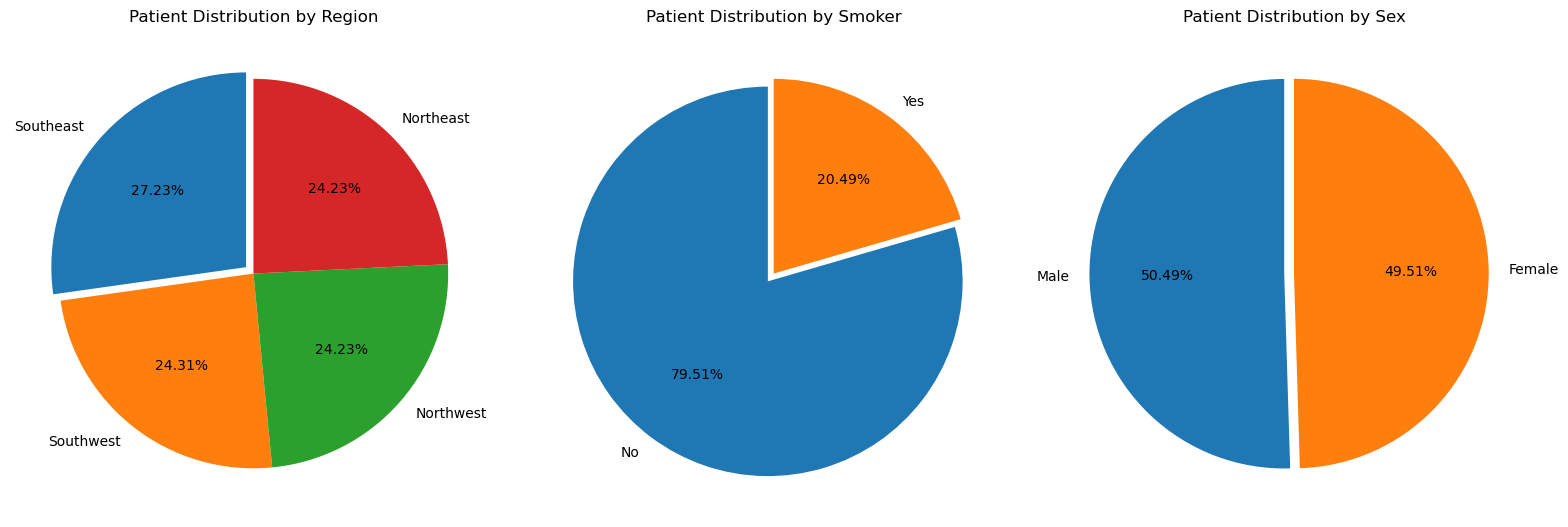

In [13]:
# Select Categorical Columns
columns = ['Region', 'Smoker', 'Sex']

# Create Subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 6),dpi=100)

# Loop Through Each Column
for ax, col in zip(axes, columns):

    counts = df[col].value_counts()

    # Automatically Highlight Largest Category
    explode = [0] * len(counts)
    largest = counts.values.argmax()
    explode[largest] = 0.05

    # Create Pie Chart
    ax.pie(
        counts.values,
        labels=counts.index,
        autopct='%1.2f%%',
        startangle=90,
        explode=explode
    )

    ax.set_title(f'Patient Distribution by {col}')

plt.tight_layout()
plt.show()

### Patient Distribution by Region, Smoking Status, and Sex

Pie charts were used to examine the distribution of categorical features.

- **Region:** Southeast has the largest share of patients (27.23%), while the remaining regions each account for approximately 24%.
- **Smoking Status:** 79.51% of patients are non-smokers, while 20.49% are smokers.
- **Sex:** The dataset is nearly balanced, with 50.49% male and 49.51% female patients.

**Key Finding:** The dataset is relatively balanced across regions and sex, but non-smokers represent the majority of observations.

### Step 4.7 - GroupBY Analysis

In [45]:
# Average Charges by Smoking Status
smoker_charges = df.groupby('Smoker')['Charges'].mean()

display(smoker_charges.round(2))

Smoker
No      8440.66
Yes    32050.23
Name: Charges, dtype: float64

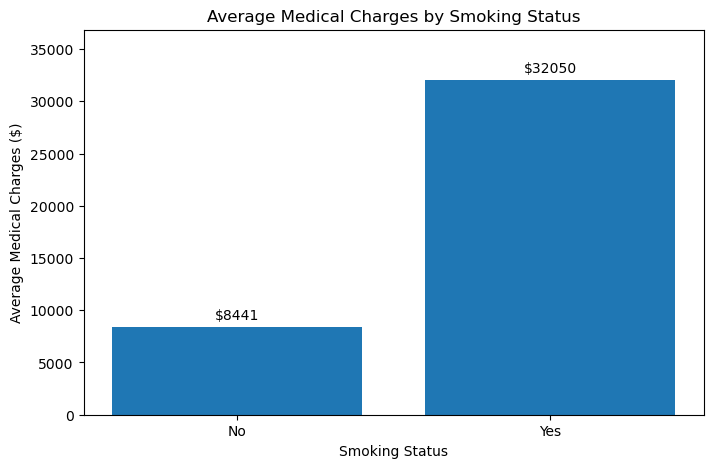

In [46]:
plt.figure(figsize=(8, 5))

bars = plt.bar(smoker_charges.index, smoker_charges.values)

plt.bar_label(bars, fmt='$%.0f', padding=3)

plt.title('Average Medical Charges by Smoking Status')
plt.xlabel('Smoking Status')
plt.ylabel('Average Medical Charges ($)')
plt.ylim(0, smoker_charges.max() * 1.15)
plt.grid(False)

plt.show()

In [48]:
# Average Charges by Region and Smoking Status
region_smoker = df.groupby(['Region', 'Smoker'])['Charges'].mean()

display(region_smoker.round(2))

Region     Smoker
Northeast  No         9165.53
           Yes       29673.54
Northwest  No         8582.47
           Yes       30192.00
Southeast  No         8032.22
           Yes       34845.00
Southwest  No         8019.28
           Yes       32269.06
Name: Charges, dtype: float64

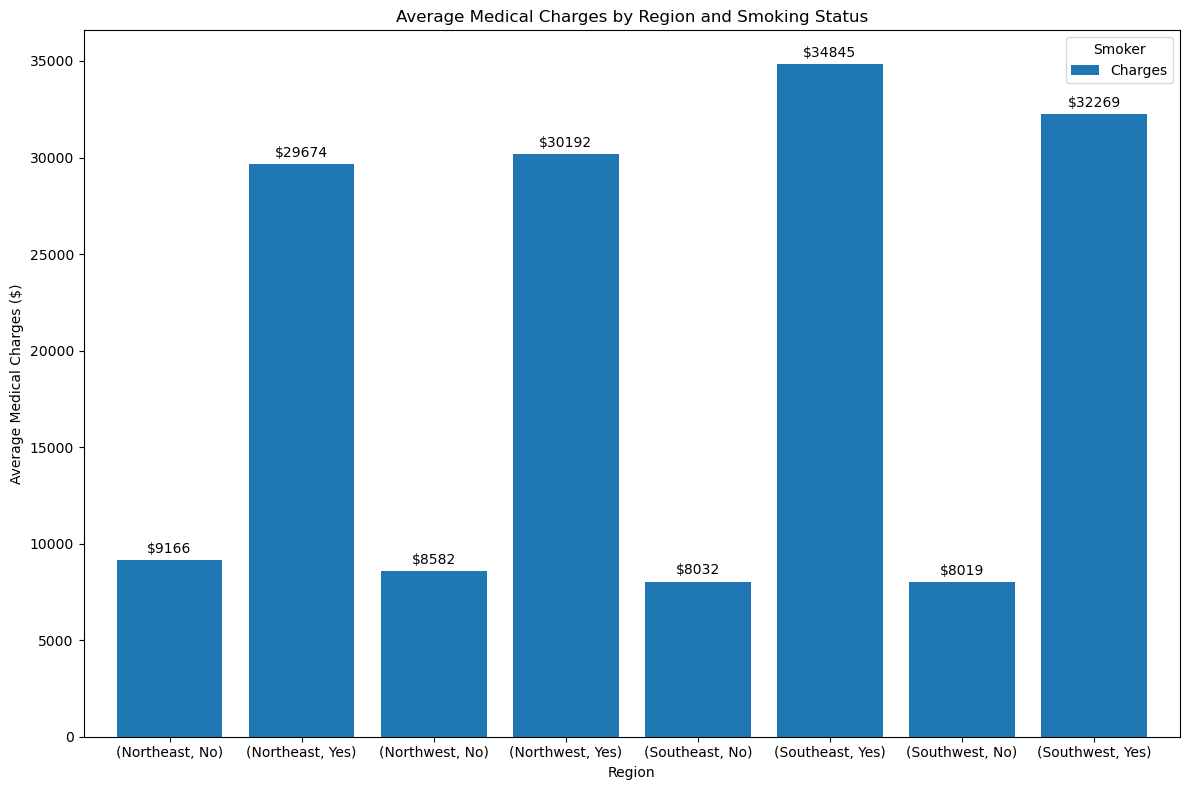

In [51]:
# Create Grouped Bar Chart
ax = region_smoker.plot(kind='bar',figsize=(12, 8),width=0.8)

# Add Dollar Labels Above Each Bar
for container in ax.containers:
    ax.bar_label(container, fmt='$%.0f', padding=3)

# Format Chart
plt.title('Average Medical Charges by Region and Smoking Status')
plt.xlabel('Region')
plt.ylabel('Average Medical Charges ($)')
plt.xticks(rotation=0)
plt.legend(title='Smoker')
plt.grid(False)

plt.tight_layout()
plt.show()

## Step 5 - Feature and Target Selection

Identify the independent variables (X) and dependent variable (y).

- X: Features used to make predictions.
- y: Target variable we want to predict.

In [14]:
# column names
features = ['Age','Bmi','Children']
target = 'Charges'

X = df[features]
y = df[target]

In [15]:
def select_features(df, target, exclude=None):

    df = df.copy()

    if exclude is None:
        exclude = []

    # Select All Features Except Target
    X = df.drop(columns=[target] + exclude)

    # Select Target
    y = df[target]

    print('Feature Selection'.center(50, '='))
    print(f'Target Variable: {target}')
    print(f'Number of Features: {X.shape[1]}')
    print(f'Feature Names: {X.columns.to_list()}')

    return X, y


# Run Function
X, y = select_features(df, target='Charges')

================Feature Selection=================
Target Variable: Charges
Number of Features: 6
Feature Names: ['Age', 'Sex', 'Bmi', 'Children', 'Smoker', 'Region']


## Step 6 - Train-Test Split

Split the dataset into training and testing sets.

- Training Data (70%): Used to train the model.
- Testing Data (30%): Used to evaluate the model.
- Random State: Ensures reproducible results.

In [16]:
def split_data(X, y, test_size=0.30, random_state=42):

    # Split Dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state
    )

    # Display Information
    print('Train-Test Split'.center(50, '='))
    print(f'Training Rows: {X_train.shape[0]}')
    print(f'Testing Rows: {X_test.shape[0]}')
    print(f'Training Percentage: {(1-test_size)*100:.0f}%')
    print(f'Testing Percentage: {test_size*100:.0f}%')

    return X_train, X_test, y_train, y_test


# Run Function
X_train, X_test, y_train, y_test = split_data(X, y)

=================Train-Test Split=================
Training Rows: 935
Testing Rows: 402
Training Percentage: 70%
Testing Percentage: 30%


## Step 7 - Data Preprocessing

Prepare numerical features for linear regression.

- Fill missing values using the training data's median.
- Optionally standardize numerical features.
- Apply the same transformations to training and testing data.
- Prevent data leakage.

### Step 7.1 - Identify Feature Types
- Automatically identify numerical features: Age, BMI, and Children.
- Identify categorical features: Sex, Smoker, and Region.

In [18]:
# Identify Numerical Columns
numerical_cols = X_train.select_dtypes(
    include='number'
).columns.tolist()

# Identify Categorical Columns
categorical_cols = X_train.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

print('Numerical Features:', numerical_cols)
print('Categorical Features:', categorical_cols)

Numerical Features: ['Age', 'Bmi', 'Children']
Categorical Features: ['Sex', 'Smoker', 'Region']


### Step 7.2 - Numerical Preprocessing
- Use `SimpleImputer` to replace missing numerical values with the median.
- Apply `StandardScaler` to standardize numerical features.

In [19]:
# Numerical Preprocessing Pipeline
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### Step 7.3 - Categorical Preprocessing
- Use `SimpleImputer` to replace missing categorical values with the most frequent category.
- Apply `OneHotEncoder` to convert categorical values into numerical indicators.
- Drop the first category as a reference to avoid redundant predictors.

In [20]:
# Step 7.3: Categorical Preprocessing Pipeline

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

### Step 7.4 - Combine Pipelines
- Use `ColumnTransformer` to combine numerical and categorical preprocessing.
- Apply the appropriate transformations to each feature type.

In [21]:
# Step 7.4: Combine Preprocessing Pipelines
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

### Step 7.5 - Fit and Transform Training and Testing Data

In [22]:
# Step 7.5: Fit and Transform Data

# Fit on Training Data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform Testing Data
X_test_processed = preprocessor.transform(X_test)

# Display Results
print('Data Preprocessing Complete'.center(50, '='))
print(f'Training Shape: {X_train_processed.shape}')
print(f'Testing Shape: {X_test_processed.shape}')

===========Data Preprocessing Complete============
Training Shape: (935, 8)
Testing Shape: (402, 8)


### Step 7.6 - Verify Preprocessed Data

In [23]:
# Step 7.6: Verify Preprocessed Data

# Get Feature Names
feature_names = preprocessor.get_feature_names_out()

# Convert Results to DataFrames
X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

# Display Information
print('Preprocessed Data Verification'.center(50, '='))

print(f'Training Shape: {X_train_processed.shape}')
print(f'Testing Shape: {X_test_processed.shape}')

print('\nMissing Values:')
print(X_train_processed.isnull().sum().sum())
print(X_test_processed.isnull().sum().sum())

print('\nFeature Names:')
print(X_train_processed.columns.to_list())

display(X_train_processed.head())

==========Preprocessed Data Verification==========
Training Shape: (935, 8)
Testing Shape: (402, 8)

Missing Values:
0
0

Feature Names:
['num__Age', 'num__Bmi', 'num__Children', 'cat__Sex_Male', 'cat__Smoker_Yes', 'cat__Region_Northwest', 'cat__Region_Southeast', 'cat__Region_Southwest']


,num__Age,num__Bmi,num__Children,cat__Sex_Male,cat__Smoker_Yes,cat__Region_Northwest,cat__Region_Southeast,cat__Region_Southwest
138,1.071358,0.212671,1.599870,0.0,0.0,0.0,1.0,0.0
381,1.142828,0.010871,-0.905789,1.0,1.0,0.0,0.0,0.0
292,-1.001264,2.478147,0.764650,1.0,1.0,0.0,1.0,0.0
1089,0.571070,0.925200,-0.905789,1.0,1.0,0.0,1.0,0.0
892,0.571070,1.381949,0.764650,1.0,1.0,0.0,1.0,0.0


In [25]:
def preprocess_data(X_train, X_test, scale=False):

    # Create Copies
    X_train = X_train.copy()
    X_test = X_test.copy()

    # Identify Numerical and Categorical Columns
    numerical_cols = X_train.select_dtypes(
        include='number'
    ).columns.tolist()

    categorical_cols = X_train.select_dtypes(
        include=['object', 'string', 'category']
    ).columns.tolist()

    # Numerical Preprocessing Pipeline
    numerical_steps = [
        ('imputer', SimpleImputer(strategy='median'))
    ]

    if scale:
        numerical_steps.append(
            ('scaler', StandardScaler())
        )

    numerical_pipeline = Pipeline(numerical_steps)

    # Categorical Preprocessing Pipeline
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    # Combine Pipelines
    preprocessor = ColumnTransformer([
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ])

    # Fit and Transform
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    # Get Feature Names
    feature_names = preprocessor.get_feature_names_out()

    # Convert to DataFrames
    X_train_processed = pd.DataFrame(
        X_train_processed,
        columns=feature_names,
        index=X_train.index
    )

    X_test_processed = pd.DataFrame(
        X_test_processed,
        columns=feature_names,
        index=X_test.index
    )

    # Display Information
    print('Data Preprocessing Complete'.center(50, '='))

    print(f'Numerical Features: {numerical_cols}')
    print(f'Categorical Features: {categorical_cols}')
    print(f'Scaling Applied: {scale}')

    print(f'\nTraining Shape: {X_train_processed.shape}')
    print(f'Testing Shape: {X_test_processed.shape}')

    print(f'\nTraining Missing Values: {X_train_processed.isnull().sum().sum()}')
    print(f'Testing Missing Values: {X_test_processed.isnull().sum().sum()}')

    print(f'\nProcessed Features: {feature_names.tolist()}')

    return X_train_processed, X_test_processed, preprocessor


# Run Function
X_train_processed, X_test_processed, preprocessor = preprocess_data(
    X_train,
    X_test,
    scale=True
)

display(X_train_processed.head())

===========Data Preprocessing Complete============
Numerical Features: ['Age', 'Bmi', 'Children']
Categorical Features: ['Sex', 'Smoker', 'Region']
Scaling Applied: True

Training Shape: (935, 8)
Testing Shape: (402, 8)

Training Missing Values: 0
Testing Missing Values: 0

Processed Features: ['num__Age', 'num__Bmi', 'num__Children', 'cat__Sex_Male', 'cat__Smoker_Yes', 'cat__Region_Northwest', 'cat__Region_Southeast', 'cat__Region_Southwest']


,num__Age,num__Bmi,num__Children,cat__Sex_Male,cat__Smoker_Yes,cat__Region_Northwest,cat__Region_Southeast,cat__Region_Southwest
138,1.071358,0.212671,1.599870,0.0,0.0,0.0,1.0,0.0
381,1.142828,0.010871,-0.905789,1.0,1.0,0.0,0.0,0.0
292,-1.001264,2.478147,0.764650,1.0,1.0,0.0,1.0,0.0
1089,0.571070,0.925200,-0.905789,1.0,1.0,0.0,1.0,0.0
892,0.571070,1.381949,0.764650,1.0,1.0,0.0,1.0,0.0


## Step 8 - Model Training

Train a Linear Regression model using the preprocessed training data.

- Initialize the regression model.
- Fit the model using X_train and y_train.
- Display the intercept and coefficients.
- Return the trained model for future predictions.

In [27]:
def train_model(X_train, y_train):

    # Initialize Model
    model = LinearRegression()

    # Train Model
    model.fit(X_train, y_train)

    # Display Information
    print('Linear Regression Model Training'.center(50, '='))
    print(f'Training Rows: {X_train.shape[0]}')
    print(f'Number of Features: {X_train.shape[1]}')
    print(f'Model Intercept: {model.intercept_:.3f}')

    # Model Coefficients
    coefficients = pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': model.coef_
    })

    print('\n')
    print('Model Coefficients'.center(50, '='))
    display(coefficients)

    print('\nModel Training Complete.')

    return model


# Run Function
model = train_model(X_train_processed, y_train)

=========Linear Regression Model Training=========
Training Rows: 935
Number of Features: 8
Model Intercept: 8905.453


================Model Coefficients================


,Feature,Coefficient
0,num__Age,3515.420056
1,num__Bmi,1977.132349
2,num__Children,625.171278
3,cat__Sex_Male,-111.907161
4,cat__Smoker_Yes,22874.446407
5,cat__Region_Northwest,-465.746596
6,cat__Region_Southeast,-936.099326
7,cat__Region_Southwest,-765.583886



Model Training Complete.


## Step 9 - Model Predictions

Generate predictions using the trained regression model.

- Predict values using the testing dataset.
- Compare actual and predicted values.
- Calculate residual errors.
- Return the predictions and results DataFrame.

In [29]:
def model_predictions(model, X_test, y_test):

    # Generate Predictions
    predictions = model.predict(X_test)

    # Create Results DataFrame
    results = pd.DataFrame({
        'Actual': np.asarray(y_test).ravel(),
        'Predicted': predictions.ravel()
    })

    # Calculate Residuals
    results['Residual'] = results['Actual'] - results['Predicted']

    # Display Information
    print('Model Predictions'.center(50, '='))
    print(f'Total Predictions: {len(predictions)}')

    print('\n')
    print('Actual vs Predicted Values'.center(50, '='))
    display(results.head(10).round(3))

    return predictions, results


# Run Function
test_predictions, results = model_predictions(
    model,
    X_test_processed,
    y_test
)

================Model Predictions=================
Total Predictions: 402


============Actual vs Predicted Values============


,Actual,Predicted,Residual
0,8688.859,8075.920,612.939
1,5708.867,5499.003,209.864
2,11436.738,14345.712,-2908.974
3,38746.355,31428.204,7318.151
4,4463.205,8874.782,-4411.577
5,9304.702,13108.236,-3803.534
6,38511.628,30222.446,8289.182
7,2150.469,1224.760,925.709
8,7345.727,10576.434,-3230.707
9,10264.442,11204.405,-939.963


## Step 10 - Model Evaluation

Evaluate the regression model using:

- **MAE:** Mean Absolute Error
- **MSE:** Mean Squared Error
- **RMSE:** Root Mean Squared Error
- **R²:** Coefficient of Determination

Lower MAE, MSE, and RMSE values indicate better predictions.
Higher R² values generally indicate better model fit.

===========Regression Model Evaluation============
Mean Absolute Error: 4181.816
Mean Squared Error: 38940169.923
Root Mean Squared Error: 6240.206
R-Squared: 0.7724


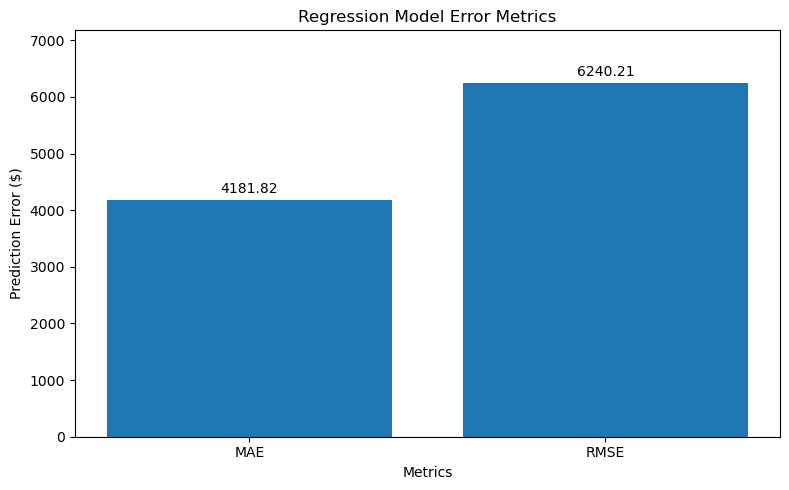

,Metric,Value
0,MAE,4.181816e+03
1,MSE,3.894017e+07
2,RMSE,6.240206e+03
3,R-Squared,7.720000e-01


In [32]:
def evaluate_model(y_test, test_predictions, plot=True):

    # Calculate Evaluation Metrics
    mae = mean_absolute_error(y_test, test_predictions)
    mse = mean_squared_error(y_test, test_predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, test_predictions)

    # Display Model Evaluation
    print('Regression Model Evaluation'.center(50, '='))

    print(f'Mean Absolute Error: {mae:.3f}')
    print(f'Mean Squared Error: {mse:.3f}')
    print(f'Root Mean Squared Error: {rmse:.3f}')
    print(f'R-Squared: {r2:.4f}')

    # Create Metrics DataFrame
    evaluation = pd.DataFrame({
        'Metric': ['MAE', 'MSE', 'RMSE', 'R-Squared'],
        'Value': [mae, mse, rmse, r2]
    })

    # Plot Evaluation Metrics
    if plot:

        plt.figure(figsize=(8, 5))

        metrics = ['MAE', 'RMSE']
        values = [mae, rmse]

        bars = plt.bar(metrics, values)

        # Add Values Above Bars
        plt.bar_label(bars, fmt='%.2f', padding=3)

        # Format Chart
        plt.title('Regression Model Error Metrics')
        plt.xlabel('Metrics')
        plt.ylabel('Prediction Error ($)')
        plt.ylim(0, max(values) * 1.15)
        plt.grid(False)

        plt.tight_layout()
        plt.show()

    return evaluation


# Run Function
evaluation = evaluate_model(y_test, test_predictions)

display(evaluation.round(3))

## Step 11 - Model Diagnostics

Evaluate regression model performance using three visualizations:

- **Actual vs. Predicted:** Compare predictions with actual values.
- **Residual Plot:** Identify patterns and unequal error variance.
- **Residual Distribution:** Examine the shape and spread of prediction errors.

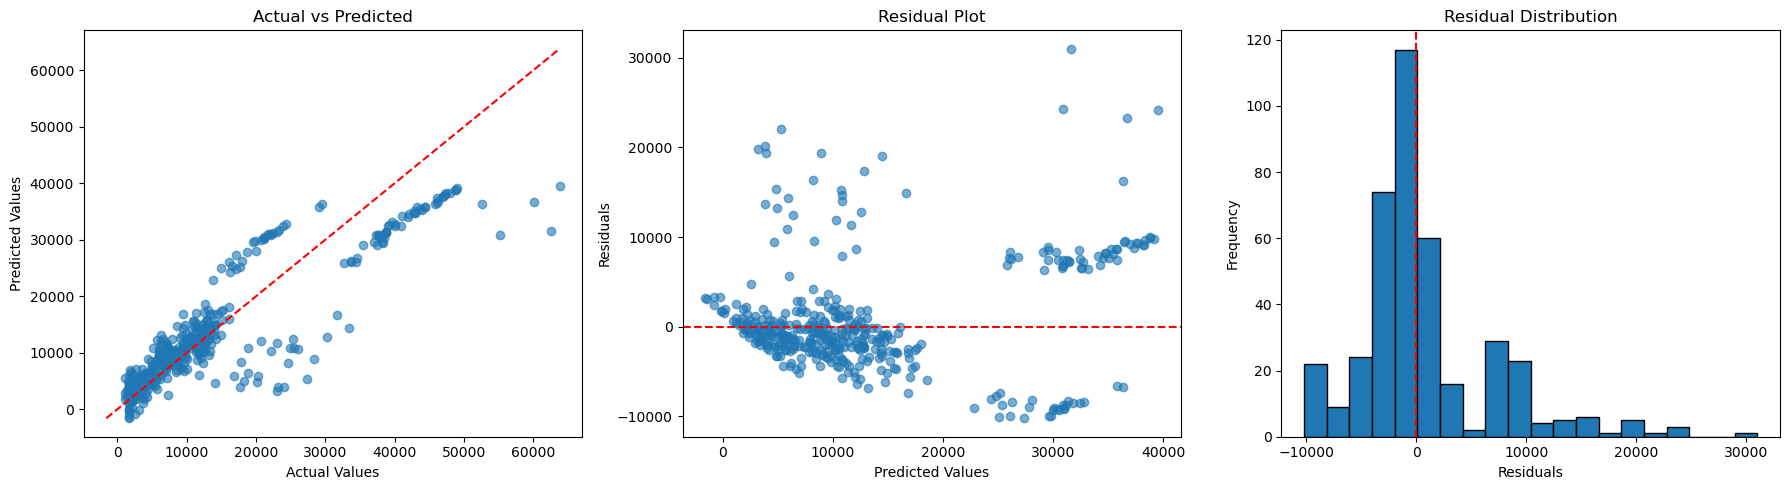

================Model Diagnostics=================
Total Residuals: 402
Mean Residual: 739.993
Standard Deviation: 6196.175


In [33]:
def model_diagnostics(y_test, test_predictions):

    # Calculate Residuals
    actual = np.asarray(y_test).ravel()
    predicted = np.asarray(test_predictions).ravel()

    residuals = actual - predicted

    # Create Subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Plot 1: Actual vs Predicted
    axes[0].scatter(actual, predicted, alpha=0.6)

    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())

    axes[0].plot([low, high], [low, high], 'r--')

    axes[0].set_title('Actual vs Predicted')
    axes[0].set_xlabel('Actual Values')
    axes[0].set_ylabel('Predicted Values')
    axes[0].grid(False)

    # Plot 2: Residual Plot
    axes[1].scatter(predicted, residuals, alpha=0.6)
    axes[1].axhline(0, color='red', linestyle='--')

    axes[1].set_title('Residual Plot')
    axes[1].set_xlabel('Predicted Values')
    axes[1].set_ylabel('Residuals')
    axes[1].grid(False)

    # Plot 3: Residual Distribution
    axes[2].hist(residuals, bins=20, edgecolor='black')
    axes[2].axvline(0, color='red', linestyle='--')

    axes[2].set_title('Residual Distribution')
    axes[2].set_xlabel('Residuals')
    axes[2].set_ylabel('Frequency')
    axes[2].grid(False)

    # Display Plots
    plt.tight_layout()
    plt.show()

    # Display Information
    print('Model Diagnostics'.center(50, '='))
    print(f'Total Residuals: {len(residuals)}')
    print(f'Mean Residual: {np.mean(residuals):.3f}')
    print(f'Standard Deviation: {np.std(residuals):.3f}')

    return residuals


# Run Function
residuals = model_diagnostics(y_test, test_predictions)

## Step 12 - Model Interpretation

Interpret the trained Linear Regression model.

- Display the model intercept.
- Identify each feature's coefficient.
- Visualize positive and negative coefficients.
- Understand how features relate to predicted values.

===============Model Interpretation===============
Model: LinearRegression
Intercept: 8905.453


===============Feature Coefficients===============


,Feature,Coefficient
4,cat__Smoker_Yes,22874.446
0,num__Age,3515.420
1,num__Bmi,1977.132
2,num__Children,625.171
3,cat__Sex_Male,-111.907
5,cat__Region_Northwest,-465.747
7,cat__Region_Southwest,-765.584
6,cat__Region_Southeast,-936.099


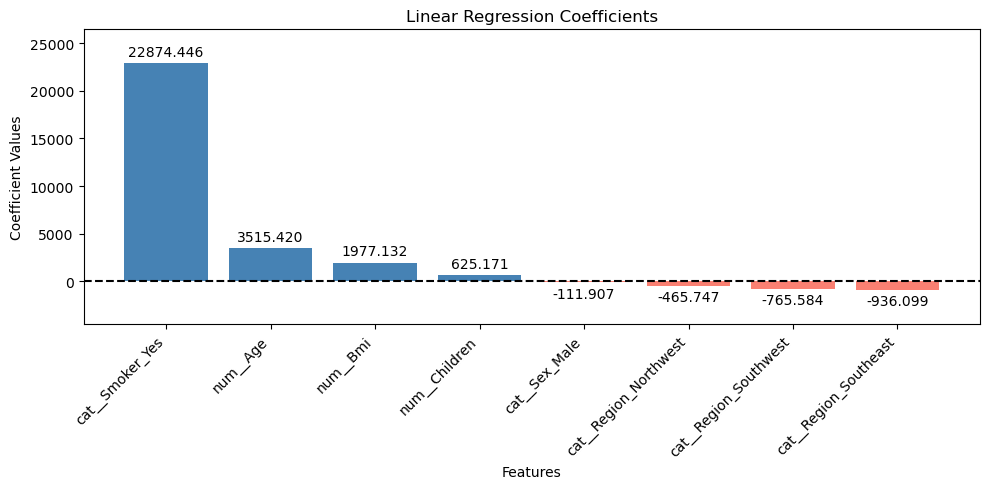

In [35]:
def interpret_model(model, X_train, plot=True):

    # Get Model Coefficients
    coefficients = pd.DataFrame({
        'Feature': X_train.columns,
        'Coefficient': model.coef_
    })

    # Sort Coefficients
    coefficients = coefficients.sort_values(
        by='Coefficient',
        ascending=False
    )

    # Display Model Information
    print('Model Interpretation'.center(50, '='))
    print(f'Model: {type(model).__name__}')
    print(f'Intercept: {model.intercept_:.3f}')

    print('\n')
    print('Feature Coefficients'.center(50, '='))
    display(coefficients.round(3))

    # Optional Coefficient Plot
    if plot:

        plt.figure(figsize=(10, 5))

        colors = [
            'steelblue' if x >= 0 else 'salmon'
            for x in coefficients['Coefficient']
        ]

        bars = plt.bar(
            coefficients['Feature'],
            coefficients['Coefficient'],
            color=colors
        )

        plt.bar_label(bars, fmt='%.3f', padding=3)

        plt.axhline(0, color='black', linestyle='--')

        plt.title('Linear Regression Coefficients')
        plt.xlabel('Features')
        plt.ylabel('Coefficient Values')
        plt.xticks(rotation=45, ha='right')
        plt.grid(False)

        plt.margins(y=0.15)
        plt.tight_layout()
        plt.show()

    return coefficients


# Run Function
coefficients = interpret_model(model, X_train_processed)

### Step 13: Cross-Validation

In [42]:
# Create Pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Run 10-Fold Cross-Validation
scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=10,
    scoring='r2'
)

# Display Results
print('Cross-Validation Results'.center(50, '='))

print(f'R² Scores: {scores.round(3)}')
print(f'Average R²: {scores.mean():.3f}')
print(f'Standard Deviation: {scores.std():.3f}')

=============Cross-Validation Results=============
R² Scores: [0.731 0.72  0.739 0.781 0.65  0.696 0.732 0.77  0.645 0.765]
Average R²: 0.723
Standard Deviation: 0.045


In [44]:
from sklearn.linear_model import Ridge, Lasso

# Define Models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0, max_iter=10000)
}

# Compare Models
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=10,
        scoring='r2'
    )

    results.append({
        'Model': name,
        'Average R2': scores.mean(),
        'Std Dev': scores.std()
    })

# Display Results
comparison = pd.DataFrame(results)

print('Model Comparison Results'.center(50, '='))
display(comparison.round(4))

=============Model Comparison Results=============


,Model,Average R2,Std Dev
0,Linear Regression,0.7230,0.0447
1,Ridge Regression,0.7231,0.0442
2,Lasso Regression,0.7230,0.0447



### Step 14: Model Comparison Findings

Linear Regression, Ridge Regression, and Lasso Regression produced nearly identical results during 10-fold cross-validation.

- Linear Regression achieved an average R² of 0.7230.
- Ridge Regression achieved an average R² of 0.7231.
- Lasso Regression achieved an average R² of 0.7230.

Although Ridge performed slightly better, the difference was negligible. Therefore, Linear Regression was selected as the final model because of its simplicity and interpretability.

The results suggest that adding regularization with the tested parameters does not meaningfully improve predictive performance.


## Step 15 - Final Results and Conclusion

### Project Summary

This project developed a Linear Regression model to predict individual medical insurance charges using demographic, lifestyle, and regional features.

The dataset included 1,337 observations after duplicate removal. Numerical and categorical features were preprocessed before model training.

### Final Model Performance

- **R² Score:** 0.7722
- **Mean Absolute Error (MAE):** $4,181.82
- **Root Mean Squared Error (RMSE):** $6,240.21
- **Cross-Validation Average R²:** 0.723

### Model Comparison

Linear Regression, Ridge Regression, and Lasso Regression produced nearly identical cross-validation results.

Linear Regression was selected as the final model because it offered similar predictive performance with simpler interpretation.

### Conclusion

The Linear Regression model explained approximately 77.22% of the variation in medical insurance charges on the test dataset.

Although the model demonstrated reasonable predictive performance, prediction errors remain significant, particularly for some high-cost patients.

### Future Improvements

- Experiment with Random Forest and Gradient Boosting.
- Investigate nonlinear relationships and interaction effects.
- Perform hyperparameter tuning.
- Compare performance using additional evaluation metrics.
- Analyze prediction errors for high-cost patients.